# 05 — Referência supervisionada (teto de comparação)
**Não é o objetivo do TCC**: serve para saber quanto de sinal CTR × TCM existe nas features, dando contexto aos
resultados não supervisionados do notebook 04.

Cuidado central: janelas do mesmo participante são altamente correlacionadas → toda validação é **agrupada por
participante** (leave-one-subject-out). Split aleatório por janela vaza informação e infla métricas — mostrado abaixo.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut, StratifiedKFold, cross_val_predict, permutation_test_score
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, f1_score

from src.data_io import PROCESSED_DIR, ROOT

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0

feat_w = pd.read_parquet(PROCESSED_DIR / "features_windows.parquet")
feat_s = pd.read_parquet(PROCESSED_DIR / "features_subjects.parquet")
ID_COLS = ["subject", "group", "sex", "window"]
FEATS = [c for c in feat_w.columns if c not in ID_COLS]

def models():
    return {
        "dummy_majoritaria": DummyClassifier(strategy="most_frequent"),
        "logreg_l2": make_pipeline(StandardScaler(), PCA(0.95, random_state=SEED),
                                   LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
        "svm_rbf": make_pipeline(StandardScaler(), PCA(0.95, random_state=SEED),
                                 SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED)),
        "random_forest": RandomForestClassifier(450, class_weight="balanced", random_state=SEED, n_jobs=-1),  # 450 árvores como na tese
    }

def scores(y, proba):
    pred = (proba >= 0.5).astype(int)
    return {"bal_acc": balanced_accuracy_score(y, pred), "AUC": roc_auc_score(y, proba), "F1_TCM": f1_score(y, pred)}

## Nível participante — leave-one-subject-out (n=38)

In [2]:
Xs, ys = feat_s[FEATS].to_numpy(), (feat_s.group == "TCM").astype(int).to_numpy()
rows = []
for name, m in models().items():
    proba = cross_val_predict(m, Xs, ys, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    rows.append({"setup": "participante_LOSO", "model": name, **scores(ys, proba)})
pd.DataFrame(rows).round(3)

,setup,model,bal_acc,AUC,F1_TCM
0,participante_LOSO,dummy_majoritaria,0.500,0.500,0.000
1,participante_LOSO,logreg_l2,0.580,0.577,0.556
2,participante_LOSO,svm_rbf,0.581,0.482,0.444
3,participante_LOSO,random_forest,0.480,0.525,0.345


## Teste de permutação (nível participante)
p-valor para "o modelo é melhor que o acaso". Com n=38, variância alta: interpretar com cautela.

In [3]:
perm = []
for name in ["logreg_l2", "random_forest"]:
    score, perm_scores, p = permutation_test_score(
        models()[name], Xs, ys, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
        scoring="balanced_accuracy", n_permutations=200, random_state=SEED, n_jobs=-1)
    perm.append({"model": name, "bal_acc_5fold": score, "perm_mean": perm_scores.mean(), "p_value": p})
pd.DataFrame(perm).round(3)

,model,bal_acc_5fold,perm_mean,p_value
0,logreg_l2,0.665,0.502,0.070
1,random_forest,0.568,0.500,0.204


## Nível janela — leave-one-subject-out vs. split aleatório (demonstração de vazamento)
Predição do participante = média das probabilidades das suas janelas.

In [4]:
Xw, yw, gw = feat_w[FEATS].to_numpy(), (feat_w.group == "TCM").astype(int).to_numpy(), feat_w.subject.to_numpy()
for cv_name, cv, groups in [("janela_LOSO", LeaveOneGroupOut(), gw),
                            ("janela_split_aleatorio_VAZA", StratifiedKFold(10, shuffle=True, random_state=SEED), None)]:
    for name in ["logreg_l2", "random_forest"]:
        proba = cross_val_predict(models()[name], Xw, yw, cv=cv, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
        subj = pd.DataFrame({"s": gw, "p": proba, "y": yw}).groupby("s").mean()
        rows.append({"setup": cv_name, "model": name, **scores(yw, proba),
                     **{f"subj_{k}": v for k, v in scores(subj.y.astype(int), subj.p).items()}})

ref = pd.DataFrame(rows)
ref.to_csv(ROOT / "reports" / "05_referencia_supervisionada.csv", index=False)
ref.round(3)

,setup,model,bal_acc,AUC,F1_TCM,subj_bal_acc,subj_AUC,subj_F1_TCM
0,participante_LOSO,dummy_majoritaria,0.500,0.500,0.000,NaN,NaN,NaN
1,participante_LOSO,logreg_l2,0.580,0.577,0.556,NaN,NaN,NaN
2,participante_LOSO,svm_rbf,0.581,0.482,0.444,NaN,NaN,NaN
3,participante_LOSO,random_forest,0.480,0.525,0.345,NaN,NaN,NaN
4,janela_LOSO,logreg_l2,0.650,0.698,0.501,0.574,0.627,0.529
5,janela_LOSO,random_forest,0.620,0.734,0.410,0.576,0.661,0.400
6,janela_split_aleatorio_VAZA,logreg_l2,0.970,0.993,0.948,0.976,1.000,0.971
7,janela_split_aleatorio_VAZA,random_forest,0.988,1.000,0.988,0.971,1.000,0.970


## Importância de features (RF, nível participante)

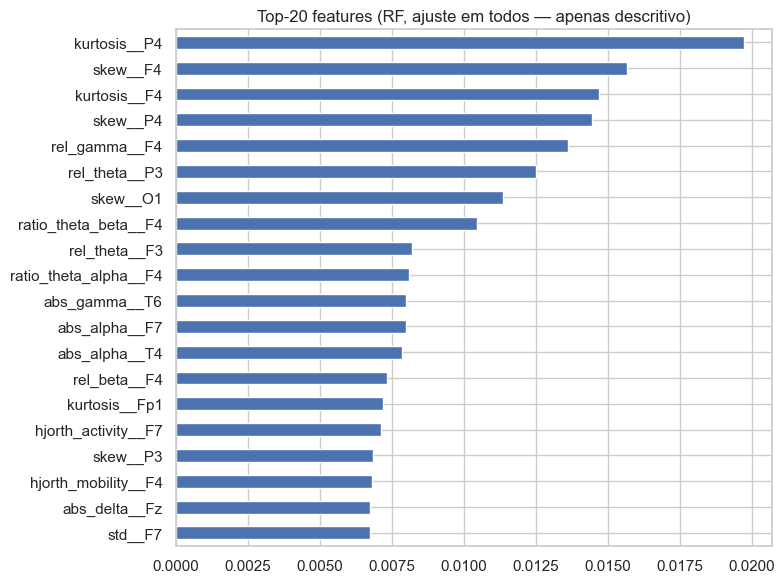

In [5]:
rf = models()["random_forest"].fit(Xs, ys)
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
imp.head(20)[::-1].plot.barh(ax=ax)
ax.set_title("Top-20 features (RF, ajuste em todos — apenas descritivo)")
fig.tight_layout(); fig.savefig(FIG / "05_rf_importancia.png", dpi=120)

## Afeto
Com 34 positivos / 3 negativos / 2 neutros (tese), **não** treinar classificador de afeto nesta fase.
A tese reporta RF com ~72% (RAB2) usando subamostragem + split 70/30 de instâncias, sem mencionar separação por
participante — se as instâncias forem janelas, o número é mais comparável ao cenário `janela_split_aleatorio_VAZA`
do que ao LOSO. Confirmar com a orientadora.